# Tutorial 5: Analyze gene pair spatial co-expression patterns in cSCC Dataset

In this tutorial, we demonstrate how to apply Redex to human cutaneous squamous cell carcinoma (cSCC) dataset. 
We curated 40 cancer-associated genes, computed cosine similarities for all 780 gene pairs based on local neighborhood expression profiles, and built a spatially resolved co-expression matrix. Using this matrix, Redex effectively prioritizes gene pairs with strong and spatially coherent co-expression patterns.

The data should be placed under  './genepair'.

## Loading packages

In [ ]:
# Installed package imports
import warnings
import scanpy as sc
import pandas as pd
import numpy as np
import os
import method



## Step 1 : Preprocess data and Construct a spot-by-pair feature matrix

In [2]:
adata = sc.read(
    "./gene pair/spatial_transcriptomics_data.h5ad")
adata.layers["count"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)  # normalize counts per cell
sc.pp.log1p(adata)  # log-transform
adata
if adata.shape[1] > 50:
    print("Running PCA...")
    sc.tl.pca(adata, n_comps=min(50, adata.shape[0]-1))
    use_rep = 'X_pca'
else:
    use_rep = 'X'

print("Computing neighborhood graph...")
sc.pp.neighbors(
    adata,
    n_neighbors=15,      
    n_pcs=30,            
    use_rep=use_rep,
    random_state=42
)
adata.write("./gene pair/spatial_transcriptomics_data_pp.h5ad")


Running PCA...
Computing neighborhood graph...


D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Helper functions

In [3]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics.pairwise import cosine_similarity
from anndata import AnnData

def compute_local_grn(
    adata,
    gene_list,
    k=10,
    similarity="unit_cosine",
    use_layer="count",         
    local_scaling=None,     
    gaussian_sigma=1.0       
):
   

    if use_layer is None:
        expr = adata[:, gene_list].X
    else:
        expr = adata[:, gene_list].layers[use_layer]

    expr = expr.toarray() if hasattr(expr, "toarray") else np.asarray(expr)
    n_spots, n_genes = expr.shape

  
    coords = adata.obs[['x_coord', 'y_coord']].values
    tree = cKDTree(coords)
    _, nbrs = tree.query(coords, k=k + 1)

  
    gene_pairs = [(i, j) for i in range(n_genes)
                  for j in range(i + 1, n_genes)]
    n_pairs = len(gene_pairs)

 
    res_matrix = np.zeros((n_spots, n_pairs), dtype=float)

   
    for s in range(n_spots):
        nbr_idx = nbrs[s]
        local_expr = expr[nbr_idx, :]   # (k+1) × n_genes

    
        if local_scaling == "minmax":
            min_val = local_expr.min(axis=0)
            max_val = local_expr.max(axis=0)
            denom = max_val - min_val
            denom[denom == 0] = 1.0
            local_expr = (local_expr - min_val) / denom

        corr = np.zeros(n_pairs, dtype=float)

        # ---------- rank / linear ----------
        if similarity in ("spearman", "pearson"):
            idx = 0
            for g1, g2 in gene_pairs:
                if similarity == "spearman":
                    r, _ = spearmanr(local_expr[:, g1], local_expr[:, g2])
                else:
                    r, _ = pearsonr(local_expr[:, g1], local_expr[:, g2])
                corr[idx] = 0.0 if np.isnan(r) else r
                idx += 1

        # ---------- vanilla cosine ----------
        elif similarity == "cosine":
            cos = cosine_similarity(local_expr.T)
            corr = cos[np.triu_indices(n_genes, k=1)]

        # ---------- vanilla gaussian ----------
        elif similarity == "gaussian":
            idx = 0
            for g1, g2 in gene_pairs:
                diff = local_expr[:, g1] - local_expr[:, g2]
                d2 = np.mean(diff ** 2)
                corr[idx] = np.exp(-d2 / (2 * gaussian_sigma ** 2))
                idx += 1

        # ---------- unit cosine ----------
        elif similarity == "unit_cosine":
            idx = 0
            for g1, g2 in gene_pairs:
                v1 = local_expr[:, g1]
                v2 = local_expr[:, g2]
                n1 = np.linalg.norm(v1)
                n2 = np.linalg.norm(v2)

                if n1 == 0 or n2 == 0:
                    corr[idx] = 0.0
                else:
                    corr[idx] = np.dot(v1 / n1, v2 / n2)
                idx += 1

        # ---------- unit gaussian ----------
        elif similarity == "unit_gaussian":
            idx = 0
            for g1, g2 in gene_pairs:
                v1 = local_expr[:, g1]
                v2 = local_expr[:, g2]
                n1 = np.linalg.norm(v1)
                n2 = np.linalg.norm(v2)

                if n1 == 0 or n2 == 0:
                    corr[idx] = 0.0
                else:
                    u1 = v1 / n1
                    u2 = v2 / n2
                    d2 = np.mean((u1 - u2) ** 2)
                    corr[idx] = np.exp(-d2 / (2 * gaussian_sigma ** 2))
                idx += 1

        else:
            raise ValueError(
                "similarity must be one of "
                "'spearman', 'pearson', "
                "'cosine', 'gaussian', "
                "'unit_cosine', 'unit_gaussian'"
            )

        res_matrix[s, :] = corr


    pair_names = [f"{gene_list[i]}_{gene_list[j]}" for i, j in gene_pairs]

    res_adata = AnnData(
        X=res_matrix,
        obs=adata.obs.copy(),
        var=pd.DataFrame(index=pair_names),
        obsm=adata.obsm.copy()
    )

    return res_adata
    

In [4]:
adata = sc.read(
    "./gene pair/spatial_transcriptomics_data_pp.h5ad")


## Step 2 : Select 40 genes and construct a gene cosine similarity matrix.

In [5]:
gene_list = [
    "KRT15", "CCL2", "COL17A1", "CXCL14", "DST",
    "CYR61", "FTH1", "MT2A", "IGFBP5", "THBS2",
    "STMN1", "HIST1H4C", "TUBA1B", "PTTG1", "HMGB2",
    "H2AFZ", "TOP2A", "UBE2C", "NUSAP1", "KIAA0101",
    "KRTDAP", "KRT10", "KRT1", "S100A7", "SBSN",
    "DMKN", "KRT16", "LYPD3", "KRT6A", "CALML5",
    "MMP10", "PTHLH", "FEZ1", "IL24", "KCNMA1",
    "INHBA", "MAGEA4", "NT5E", "LAMC2", "SLITRK6"
]

 
available_genes = [g for g in gene_list if g in adata.var_names]
missing_genes = set(gene_list) - set(available_genes)
print(f"✅ Using {len(available_genes)} genes, {len(missing_genes)} missing.")


✅ Using 40 genes, 0 missing.


In [6]:
adata_grn = compute_local_grn(
    adata,
    gene_list,
    k =10,
    similarity="unit_cosine",  # "spearman", "pearson", "cosine", "gaussian"
    use_layer="count",          # None 或 "count"
    local_scaling="None",      # None 或 "minmax"
)

adata_grn
adata_grn.write("./gene pair/knn_10.h5ad")



## Step 3 : Use SVF module to select top gene pair

Configuration

In [7]:
DATA_ROOT = './gene pair'
SAVE_ROOT = './gene pair/result'

DATASETS = {
    'spatial': {
        'h5ad_file': 'knn_10.h5ad',
        'prefix':    'knn_10',        # 输出文件名前缀
        'min_cells': 30,
    },
}

THRESHOLDS = [25, 50, 75]


## Gene pair selection

In [8]:
for dataset, cfg in DATASETS.items():
    print(f"\n{'='*50}")
    print(f"Gene selection for {dataset}")
    print(f"{'='*50}")

    # ------ Load ------
    h5ad_path = os.path.join(DATA_ROOT, f"{cfg['h5ad_file']}")
    adata = sc.read_h5ad(h5ad_path)
    print(f"X min value: {adata.X.min()}")

    # ------ Preprocess ------
    adata = method.preprocess_adata(adata, min_cells=cfg['min_cells'])
    neighbors = method.compute_neighbors(adata, k_neighbors=6)

    # ------ Compute R values at each threshold ------
    results_dict = {}
    for thre in THRESHOLDS:
        method.compute_gene_groups(adata, exp_thre=thre, num_workers=1)
        W_gs = method.compute_weight_matrices(adata, neighbors, num_workers=1)
        results, _ = method.compute_r_values(adata, W_gs, num_workers=1)
        results_dict[thre] = results

    # ------ Merge & save ------
    save_dir = os.path.join(SAVE_ROOT)
    os.makedirs(save_dir, exist_ok=True)
    prefix = cfg['prefix']

    for thre, results in results_dict.items():
        path = os.path.join(save_dir, f'{prefix}_results_{thre}.csv')
        pd.DataFrame(results).to_csv(path, index=False)
        print(f"  results_{thre} → {path}")

    merged_df = method.merge_files_and_compute_max(results_dict)
    merged_path = os.path.join(save_dir, f'{prefix}_three_top_rg-results_df.csv')
    merged_df.to_csv(merged_path, index=False)
    print(f"  merged results → {merged_path}")

    print(f"Dataset {dataset} done.")
    

D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:18: RuntimeWarning: divide by zero encountered in divide
  scale = np.where(diff != 0, (feature_range[1] - feature_range[0]) / diff, 0)



Gene selection for spatial
X min value: 0.0


Computing gene groups: 100%|███████████████████████████████████████████████████████| 703/703 [00:00<00:00, 2957.82it/s]
D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:98: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['L_g'] = adata.var.index.map(lambda x: results[x]['L_g'] if x in results else [])
Computing R values: 100%|██████████████████████████████████████████████████████████| 703/703 [00:00<00:00, 1205.72it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|██████████████████████████████████████████████████████████| 703/703 [00:00<00:00, 1267.65it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|██████████████████████████████████████████████████████████| 703/703 [00:00<00:00, 1260.28it/s]

 R_g =A_g * B_g * C_g 
  results_25 → ./gene pair/result\knn_10_results_25.csv
  results_50 → ./gene pair/result\knn_10_results_50.csv
  results_75 → ./gene pair/result\knn_10_results_75.csv
  merged results → ./gene pair/result\knn_10_three_top_rg-results_df.csv
Dataset spatial done.


## Step 4 : Draw a gene pair graph

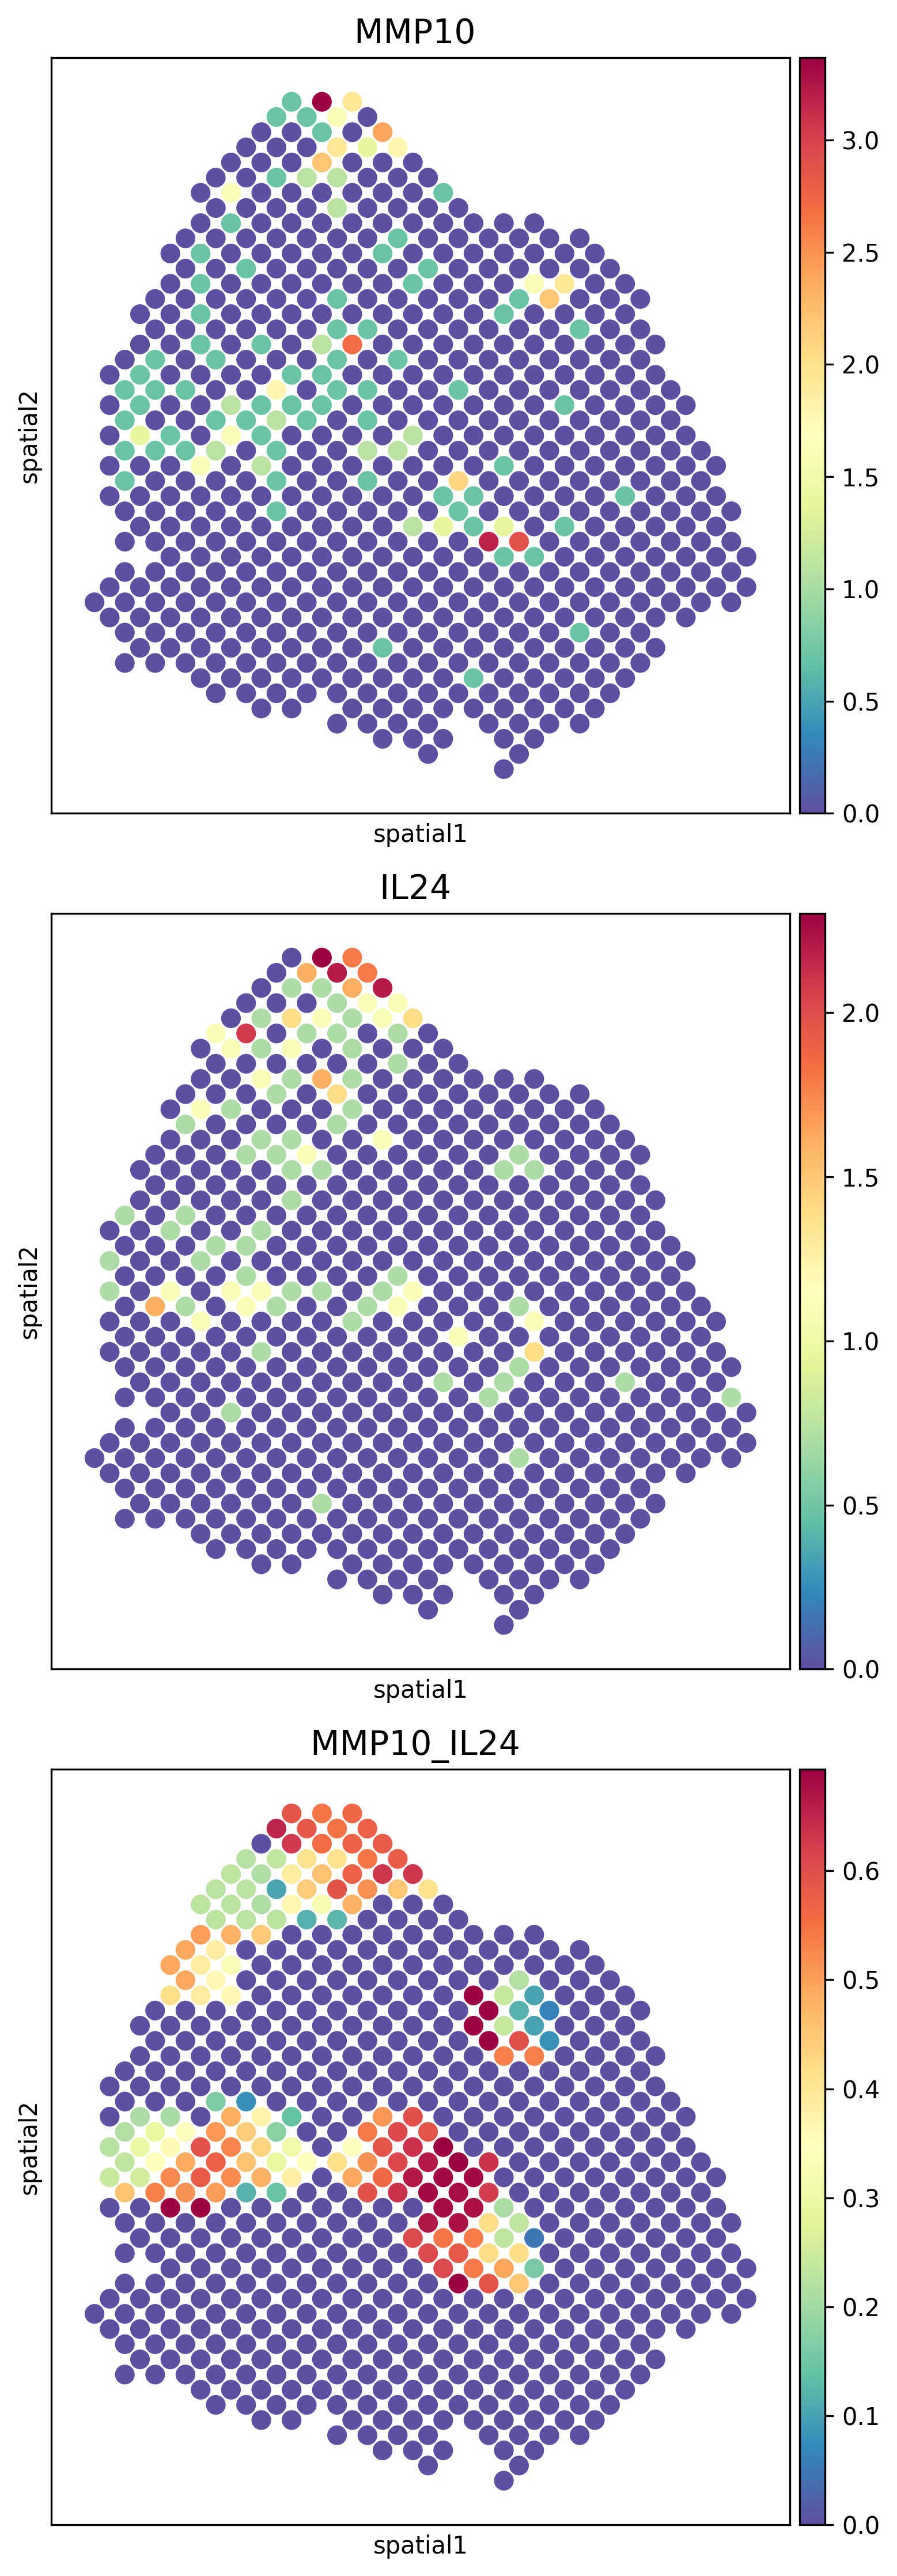

fig is done：gene pair\result\MMP10_IL24_composite.svg


In [9]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc

def plot_gene_pair_composite(
    gene_pair,
    raw_h5ad_path,
    grn_h5ad_path,
    output_dir,
    cmap="Spectral_r",
    spot_size=1.3,
    dpi=200,
    show=True,
    vmin_raw=None,
    vmax_raw=None,
    vmin_grn=None,
    vmax_grn=None,
):
  
    if "_" not in gene_pair:
        raise ValueError("g")

    gene_a, gene_b = gene_pair.split("_", 1)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

  
    adata_raw = sc.read_h5ad(raw_h5ad_path)
    adata_raw_log = adata_raw.copy()
    sc.pp.log1p(adata_raw_log)


    adata_grn = sc.read_h5ad(grn_h5ad_path)
    adata_grn_log = adata_grn.copy()
    sc.pp.log1p(adata_grn_log)


    if gene_a not in adata_raw_log.var_names:
        raise KeyError(f"{gene_a} not in AnnData")
    if gene_b not in adata_raw_log.var_names:
        raise KeyError(f"{gene_b} not in AnnData")
    if (
        gene_pair not in adata_grn_log.obs.columns
        and gene_pair not in adata_grn_log.var_names
    ):
        raise KeyError(f"{gene_pair} not in GRN AnnData")


    fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(6, 15), dpi=dpi)

    def _plot(adata, gene, ax, title, vmin=None, vmax=None):
        sc.pl.spatial(
            adata,
            color=[gene],
            cmap=cmap,
            spot_size=spot_size,
            ax=ax,
            show=False,
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(title, fontsize=14)

  
    _plot(adata_raw_log, gene_a, axes[0], f"{gene_a} ", vmin=vmin_raw, vmax=vmax_raw)
    _plot(adata_raw_log, gene_b, axes[1], f"{gene_b} ", vmin=vmin_raw, vmax=vmax_raw)
    _plot(adata_grn_log, gene_pair, axes[2], f"{gene_pair} ", vmin=vmin_grn, vmax=vmax_grn)

    plt.tight_layout()
    save_path = output_dir / f"{gene_pair}_composite.svg"
    fig.savefig(save_path, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

    print(f"fig is done：{save_path}")

if __name__ == "__main__":

    RAW_H5AD_PATH = "./gene pair/spatial_transcriptomics_data.h5ad"
    GRN_H5AD_PATH = "./gene pair/knn_10.h5ad"
    OUTPUT_DIR = "./gene pair/result"
    plot_gene_pair_composite(
        gene_pair="MMP10_IL24",
        raw_h5ad_path=RAW_H5AD_PATH,
        grn_h5ad_path=GRN_H5AD_PATH,
        output_dir=OUTPUT_DIR,
        cmap="Spectral_r",
        spot_size=1.3,
        dpi=300,
        show=True,
        vmin_raw=0,
        vmax_raw=None,
        vmin_grn=0,
        vmax_grn=None,
    )
    